# Mesh optimization — reduce geometry, keep the quality

This notebook decimates a textured 3D model (FBX/GLB/OBJ) with **quadric edge-collapse**
(Blender's engine, via `bpy`), keeps UVs + PBR textures + normal map intact, and then
**measures and visualises** how much quality each level of detail (LOD) keeps:

1. Load the original and inspect it (triangles, textures, file size)
2. Build a sweep of LODs (50 % → 1 % of the triangles)
3. Geometric error — surface deviation vs. the original (mean / p95 / max, Hausdorff)
4. Visual error — renders compared pixel-by-pixel (PSNR, SSIM)
5. Visual comparisons — beauty renders, close-ups, wireframes, deviation heat-maps, diff images
6. Auto-pick the smallest LOD that still meets your quality target, export FBX + GLB

**Requirements:** Python 3.11, `pip install bpy numpy pandas matplotlib scikit-image`

In [1]:
!pip install bpy numpy pandas matplotlib scikit-image jinja2   
import os, time, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from skimage.metrics import structural_similarity, peak_signal_noise_ratio

import bpy, bmesh
from mathutils import Vector
from mathutils.bvhtree import BVHTree
print("Blender", bpy.app.version_string)


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Blender 5.0.1


## 1 · Configuration

In [2]:
INPUT = "C:/Users/vinny/Downloads/ESTT_M06.glb" # Coloque o caminho da sua peça aqui
OUT_DIR = "C:/Users/vinny/OneDrive/Área de Trabalho/Optimization_Python/optimized" # Coloque a pasta de destino aqui           # renders + exported LODs go here

RATIOS  = [0.5, 0.25, 0.10, 0.05, 0.02, 0.01]   # fraction of triangles to keep

# Quality target used to auto-pick the final LOD (section 7)
MAX_DEVIATION = 0.0010   # max surface deviation, fraction of bbox diagonal (0.1 %)
MIN_SSIM      = 0.98     # min structural similarity of the render vs. original

RENDER_RES     = 1000    # px, square renders
RENDER_SAMPLES = 32      # Cycles samples (CPU); denoised
SMOOTH_ANGLE   = 60      # deg, edges sharper than this stay hard after decimation

os.makedirs(OUT_DIR, exist_ok=True)

## 2 · Helper functions

In [3]:
# ---------- plotting style (sequential blue ramp for ordered LODs) ----------
INK, MUTED, GRID = "#1f2328", "#6b7280", "#e5e7eb"
SEQ = ["#0d366b", "#184f95", "#256abf", "#3987e5", "#6da7ec", "#9ec5f4", "#cde2fb"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": .8,
    "figure.constrained_layout.use": True, "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9.5, "lines.linewidth": 2,
})

import contextlib, sys
@contextlib.contextmanager
def quiet():
    """Silence Blender's C-level stdout/stderr (render + exporter logs)."""
    sys.stdout.flush(); sys.stderr.flush()
    saved = os.dup(1), os.dup(2)
    null = os.open(os.devnull, os.O_WRONLY)
    os.dup2(null, 1); os.dup2(null, 2)
    import io, logging
    logging.disable(logging.CRITICAL)
    try:
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            yield
    finally:
        logging.disable(logging.NOTSET)
        os.dup2(saved[0], 1); os.dup2(saved[1], 2)
        for fd in (*saved, null): os.close(fd)

def tri_count(obj):
    return sum(len(p.vertices) - 2 for p in obj.data.polygons)

def verts_np(me, mw):
    co = np.empty(len(me.vertices) * 3, dtype=np.float32)
    me.vertices.foreach_get("co", co)
    co = co.reshape(-1, 3)
    M = np.array(mw)
    return co @ M[:3, :3].T + M[:3, 3]

def bvh_of(me, mw):
    bm = bmesh.new(); bm.from_mesh(me); bm.transform(mw)
    t = BVHTree.FromBMesh(bm); bm.free(); return t

def nearest_dist(tree, pts):
    out = np.empty(len(pts), dtype=np.float32)
    for i, p in enumerate(pts):
        out[i] = tree.find_nearest(Vector(p))[3]
    return out

# ---------- geometry ----------
def cleanup(obj, dist=1e-6):
    bm = bmesh.new(); bm.from_mesh(obj.data)
    bmesh.ops.remove_doubles(bm, verts=bm.verts, dist=dist)
    bmesh.ops.dissolve_degenerate(bm, edges=bm.edges, dist=dist)
    bmesh.ops.delete(bm, geom=[v for v in bm.verts if not v.link_faces], context="VERTS")
    bm.to_mesh(obj.data); bm.free(); obj.data.update()

def decimate(obj, ratio):
    """Quadric edge collapse: keeps UVs (interpolated), materials, triangulated output."""
    m = obj.modifiers.new("Decimate", "DECIMATE")
    m.decimate_type, m.ratio, m.use_collapse_triangulate = "COLLAPSE", ratio, True
    bpy.context.view_layer.objects.active = obj
    with quiet(): bpy.ops.object.modifier_apply(modifier=m.name)

def fix_shading(obj, angle_deg=SMOOTH_ANGLE):
    if obj.data.has_custom_normals:
        bpy.context.view_layer.objects.active = obj
        bpy.ops.mesh.customdata_custom_splitnormals_clear()
    for o in bpy.context.selected_objects: o.select_set(False)
    obj.select_set(True); bpy.context.view_layer.objects.active = obj
    bpy.ops.object.shade_smooth_by_angle(angle=math.radians(angle_deg))
    obj.select_set(False)

def export_fbx(obj, path):
    for o in bpy.context.scene.objects: o.select_set(o == obj)
    with quiet(): bpy.ops.export_scene.fbx(filepath=path, use_selection=True, object_types={"MESH"},
                             path_mode="COPY", embed_textures=True, mesh_smooth_type="FACE",
                             add_leaf_bones=False)
    obj.select_set(False)
    return os.path.getsize(path) / 1e6

def export_glb(obj, path, draco=True, image_format="AUTO"):
    for o in bpy.context.scene.objects: o.select_set(o == obj)
    with quiet(): bpy.ops.export_scene.gltf(filepath=path, export_format="GLB", use_selection=True,
                              export_image_format=image_format,
                              export_draco_mesh_compression_enable=draco,
                              export_draco_mesh_compression_level=6)
    obj.select_set(False)
    return os.path.getsize(path) / 1e6

In [4]:
# ---------- rendering (Cycles CPU, works headless) ----------
def setup_scene(obj, res=RENDER_RES, samples=RENDER_SAMPLES):
    sc = bpy.context.scene
    sc.render.engine = "CYCLES"; sc.cycles.device = "CPU"
    sc.cycles.samples = samples; sc.cycles.use_denoising = True
    sc.render.resolution_x = sc.render.resolution_y = res
    sc.render.film_transparent = False
    sc.view_settings.view_transform = "Standard"
    cs = [obj.matrix_world @ Vector(c) for c in obj.bound_box]
    lo = Vector([min(c[i] for c in cs) for i in range(3)])
    hi = Vector([max(c[i] for c in cs) for i in range(3)])
    ctr, diag = (lo + hi) / 2, (hi - lo).length
    cam = bpy.data.objects.new("cam", bpy.data.cameras.new("cam"))
    sc.collection.objects.link(cam); sc.camera = cam
    cam.data.lens = 50
    cam.location = ctr + Vector((1, -1.3, 0.75)).normalized() * diag * 1.05
    cam.rotation_euler = (ctr - cam.location).to_track_quat("-Z", "Y").to_euler()
    w = bpy.data.worlds.new("w"); sc.world = w; w.use_nodes = True
    bg = w.node_tree.nodes["Background"]
    bg.inputs[0].default_value = (0.93, 0.94, 0.95, 1); bg.inputs[1].default_value = 0.9
    sun = bpy.data.objects.new("sun", bpy.data.lights.new("sun", "SUN"))
    sun.data.energy = 3.0; sun.data.angle = math.radians(8)
    sun.rotation_euler = (math.radians(50), math.radians(10), math.radians(35))
    sc.collection.objects.link(sun)
    return diag

def make_wire_material():
    m = bpy.data.materials.new("WireOverlay"); m.use_nodes = True
    nt = m.node_tree; nt.nodes.clear()
    out = nt.nodes.new("ShaderNodeOutputMaterial")
    wire = nt.nodes.new("ShaderNodeWireframe"); wire.use_pixel_size = True
    wire.inputs[0].default_value = 0.6
    clay = nt.nodes.new("ShaderNodeBsdfDiffuse"); clay.inputs[0].default_value = (0.8, 0.8, 0.8, 1)
    ink = nt.nodes.new("ShaderNodeEmission"); ink.inputs[0].default_value = (0.05, 0.2, 0.55, 1)
    mix = nt.nodes.new("ShaderNodeMixShader")
    nt.links.new(wire.outputs[0], mix.inputs[0]); nt.links.new(clay.outputs[0], mix.inputs[1])
    nt.links.new(ink.outputs[0], mix.inputs[2]); nt.links.new(mix.outputs[0], out.inputs[0])
    return m

def make_heat_material():
    """Reads the per-vertex colour attribute 'deviation' (already colour-mapped)."""
    m = bpy.data.materials.new("Heat"); m.use_nodes = True
    nt = m.node_tree; nt.nodes.clear()
    out = nt.nodes.new("ShaderNodeOutputMaterial")
    attr = nt.nodes.new("ShaderNodeAttribute"); attr.attribute_name = "deviation"
    lw = nt.nodes.new("ShaderNodeLayerWeight"); lw.inputs[0].default_value = 0.5
    shade = nt.nodes.new("ShaderNodeMapRange")          # facing 0..1 -> brightness 1..0.55
    shade.inputs[3].default_value, shade.inputs[4].default_value = 1.0, 0.55
    mul = nt.nodes.new("ShaderNodeMix"); mul.data_type = "RGBA"; mul.blend_type = "MULTIPLY"
    mul.inputs[0].default_value = 1.0
    em = nt.nodes.new("ShaderNodeEmission")
    nt.links.new(lw.outputs["Facing"], shade.inputs[0])
    nt.links.new(attr.outputs[0], mul.inputs[6]); nt.links.new(shade.outputs[0], mul.inputs[7])
    nt.links.new(mul.outputs[2], em.inputs[0]); nt.links.new(em.outputs[0], out.inputs[0])
    return m

def render(path, override=None):
    vl = bpy.context.view_layer
    vl.material_override = override
    bpy.context.scene.render.filepath = path
    with quiet():
        bpy.ops.render.render(write_still=True)
    vl.material_override = None
    return path

def load_rgb(path):
    return mpimg.imread(path)[..., :3].astype(np.float32)

# sequential single-hue ramp for the deviation heat-map: grey (tiny) -> deep orange (large), log scale
HEAT_LO, HEAT_HI = 1e-3, 1e-1   # % of model size mapped to the ends of the ramp
def heat01(pct):
    return (np.log10(np.clip(pct, HEAT_LO, HEAT_HI)) - np.log10(HEAT_LO)) / (np.log10(HEAT_HI) - np.log10(HEAT_LO))
HEAT_STOPS = np.array([[0.78, 0.79, 0.81], [0.99, 0.80, 0.55], [0.95, 0.52, 0.18],
                       [0.78, 0.30, 0.05], [0.45, 0.14, 0.02]])
def heat_colors(v01):
    x = np.clip(v01, 0, 1) * (len(HEAT_STOPS) - 1)
    i = np.minimum(x.astype(int), len(HEAT_STOPS) - 2); f = (x - i)[:, None]
    rgb = HEAT_STOPS[i] * (1 - f) + HEAT_STOPS[i + 1] * f
    return np.c_[rgb, np.ones(len(rgb))].astype(np.float32)

def set_deviation_attr(me, dev01):
    if "deviation" in me.color_attributes:
        me.color_attributes.remove(me.color_attributes["deviation"])
    ca = me.color_attributes.new("deviation", "FLOAT_COLOR", "POINT")
    c = heat_colors(dev01); c[:, :3] = c[:, :3] ** 2.2      # sRGB -> linear for Blender
    ca.data.foreach_set("color", c.ravel())

## 3 · Load the original model

In [5]:
# bpy is imported in the setup cell and is available in this notebook.

bpy.ops.wm.read_factory_settings(use_empty=True)
t = time.time()
ext = os.path.splitext(INPUT)[1].lower()

# Estrutura if/elif explícita
with quiet():
    if ext == ".fbx":
        bpy.ops.import_scene.fbx(filepath=INPUT)
    elif ext in [".glb", ".gltf"]:
        bpy.ops.import_scene.gltf(filepath=INPUT)
    elif ext == ".obj":
        bpy.ops.wm.obj_import(filepath=INPUT)
    else:
        raise ValueError(f"Erro no pipeline: Extensão '{ext}' não suportada.")

# Coleta as malhas e une caso o modelo venha fatiado
meshes = [o for o in bpy.context.scene.objects if o.type == "MESH"]
if len(meshes) > 1:
    for o in meshes: o.select_set(True)
    bpy.context.view_layer.objects.active = meshes[0]
    bpy.ops.object.join()

# DEFINE O OBJ (A linha que estava faltando!)
obj = [o for o in bpy.context.scene.objects if o.type == "MESH"][0]

cleanup(obj)
print(f"imported in {time.time()-t:.1f}s")

ORIG_ME = obj.data.copy()
ORIG_ME.use_fake_user = True  # pristine copy
MW = obj.matrix_world.copy()
orig_tris, orig_verts = tri_count(obj), len(obj.data.vertices)
orig_file_mb = os.path.getsize(INPUT) / 1e6

tex = [(i.name, f"{i.size[0]}x{i.size[1]}", round((i.packed_file.size if i.packed_file else 0) / 1e6, 1))
       for i in bpy.data.images if i.type == "IMAGE"]
tex_mb = sum(t[2] for t in tex)
print(f"triangles {orig_tris:,} | vertices {orig_verts:,} | UV layers {len(obj.data.uv_layers)} "
      f"| materials {len(obj.data.materials)} | file {orig_file_mb:.1f} MB")
pd.DataFrame(tex, columns=["texture", "resolution", "embedded MB"])

imported in 1080.3s
triangles 10,152,725 | vertices 5,803,876 | UV layers 0 | materials 31 | file 651.6 MB


,texture,resolution,embedded MB


In [6]:
# Texture maps travel with the model untouched - decimation only changes geometry.
imgs = [i for i in bpy.data.images if i.type == "IMAGE" and i.size[0] > 0]

if len(imgs) > 0:
    fig, axs = plt.subplots(1, len(imgs), figsize=(3.2 * len(imgs), 3.4))
    for ax, im in zip(np.atleast_1d(axs), imgs):
        w, h = im.size
        px = np.empty(w * h * 4, dtype=np.float32); im.pixels.foreach_get(px)
        ax.imshow(px.reshape(h, w, 4)[::-8, ::8, :3].clip(0, 1)); ax.set_title(im.name, fontsize=8)
        ax.axis("off")
    fig.suptitle("PBR texture maps (kept as-is)", fontweight="bold"); plt.show()
else:
    print("Nenhuma textura de imagem encontrada no modelo CAD para exibir.")

Nenhuma textura de imagem encontrada no modelo CAD para exibir.


## 4 · Build the LOD sweep and measure everything

For every ratio we: restore the original mesh → decimate → fix shading → measure
**geometric deviation** in both directions (original → LOD and LOD → original, i.e. a
symmetric Hausdorff distance) → render beauty / wireframe / deviation heat-map → export FBX.

In [7]:
DIAG = setup_scene(obj)
WIRE, HEAT = make_wire_material(), make_heat_material()
ORIG_PTS  = verts_np(ORIG_ME, MW)
ORIG_TREE = bvh_of(ORIG_ME, MW)
rng = np.random.default_rng(0)

# reference renders of the original
obj.data = ORIG_ME.copy(); fix_shading(obj)
R = {1.0: dict(beauty=render(f"{OUT_DIR}/beauty_100.png"),
               wire=render(f"{OUT_DIR}/wire_100.png", WIRE))}
REF_IMG = load_rgb(R[1.0]["beauty"])

rows, DISTS = [], {}
rows.append(dict(ratio=1.0, label="original", tris=orig_tris, verts=orig_verts,
                 mean_pct=0, p95_pct=0, max_pct=0, psnr=np.inf, ssim=1.0,
                 fbx_mb=orig_file_mb, seconds=0))

for r in RATIOS:
    t0 = time.time()
    obj.data = ORIG_ME.copy()
    decimate(obj, r); fix_shading(obj)
    dt = time.time() - t0
    me = obj.data
    lod_tree, lod_pts = bvh_of(me, MW), verts_np(me, MW)

    # original -> LOD  (where detail was lost)  — all original vertices
    d_fwd = nearest_dist(lod_tree, ORIG_PTS)
    # LOD -> original  (where the LOD bulges out) — sampled
    samp = lod_pts[rng.choice(len(lod_pts), min(100_000, len(lod_pts)), replace=False)]
    d_bwd = nearest_dist(ORIG_TREE, samp)
    d_all = np.r_[d_fwd, d_bwd]
    DISTS[r] = d_fwd / DIAG * 100

    tag = f"{r*100:g}".replace(".", "_")
    R[r] = dict(beauty=render(f"{OUT_DIR}/beauty_{tag}.png"),
                wire=render(f"{OUT_DIR}/wire_{tag}.png", WIRE))

    # heat-map: paint the ORIGINAL surface by how far it is from this LOD
    heat_me = ORIG_ME.copy(); set_deviation_attr(heat_me, heat01(d_fwd / DIAG * 100))
    lod_me = obj.data; obj.data = heat_me
    R[r]["heat"] = render(f"{OUT_DIR}/heat_{tag}.png", HEAT)
    obj.data = lod_me; bpy.data.meshes.remove(heat_me)

    img = load_rgb(R[r]["beauty"])
    fbx_mb = export_fbx(obj, f"{OUT_DIR}/lod_{tag}.fbx")
    rows.append(dict(ratio=r, label=f"{r*100:g}%", tris=tri_count(obj), verts=len(me.vertices),
                     mean_pct=d_all.mean() / DIAG * 100,
                     p95_pct=np.percentile(d_all, 95) / DIAG * 100,
                     max_pct=d_all.max() / DIAG * 100,
                     psnr=peak_signal_noise_ratio(REF_IMG, img, data_range=1.0),
                     ssim=structural_similarity(REF_IMG, img, channel_axis=2, data_range=1.0),
                     fbx_mb=fbx_mb, seconds=dt))
    print(f"{r:>5.2f}  {rows[-1]['tris']:>10,} tris  max dev {rows[-1]['max_pct']:.4f}%  "
          f"SSIM {rows[-1]['ssim']:.4f}  FBX {fbx_mb:.1f} MB  ({time.time()-t0:.0f}s)")

df = pd.DataFrame(rows)

C:\Users\vinny\AppData\Local\Temp\ipykernel_28424\4150135763.py:18: DeprecationWarning: 'World.use_nodes' is expected to be removed in Blender 6.0
  w = bpy.data.worlds.new("w"); sc.world = w; w.use_nodes = True
C:\Users\vinny\AppData\Local\Temp\ipykernel_28424\4150135763.py:28: DeprecationWarning: 'Material.use_nodes' is expected to be removed in Blender 6.0
  m = bpy.data.materials.new("WireOverlay"); m.use_nodes = True
C:\Users\vinny\AppData\Local\Temp\ipykernel_28424\4150135763.py:42: DeprecationWarning: 'Material.use_nodes' is expected to be removed in Blender 6.0
  m = bpy.data.materials.new("Heat"); m.use_nodes = True


 0.50   5,076,343 tris  max dev 0.0498%  SSIM 1.0000  FBX 122.1 MB  (196s)


c:\Users\vinny\AppData\Local\Programs\Python\Python311\Lib\site-packages\skimage\metrics\simple_metrics.py:171: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


 0.25   2,538,170 tris  max dev 0.0498%  SSIM 1.0000  FBX 68.0 MB  (243s)
 0.10   1,015,268 tris  max dev 0.0498%  SSIM 1.0000  FBX 32.8 MB  (253s)
 0.05     507,634 tris  max dev 0.3724%  SSIM 1.0000  FBX 18.0 MB  (275s)
 0.02     468,173 tris  max dev 0.7933%  SSIM 1.0000  FBX 16.8 MB  (264s)
 0.01     468,173 tris  max dev 1.8450%  SSIM 1.0000  FBX 16.8 MB  (266s)


## 5 · Results table

In [8]:
show = df.assign(**{"tris kept %": df.tris / orig_tris * 100,
                    "FBX size %": df.fbx_mb / orig_file_mb * 100})
show[["label", "tris", "verts", "tris kept %", "mean_pct", "p95_pct", "max_pct",
      "psnr", "ssim", "fbx_mb", "FBX size %", "seconds"]].style.format({
    "tris": "{:,}", "verts": "{:,}", "tris kept %": "{:.1f}", "mean_pct": "{:.5f}",
    "p95_pct": "{:.4f}", "max_pct": "{:.4f}", "psnr": "{:.2f}", "ssim": "{:.4f}",
    "fbx_mb": "{:.1f}", "FBX size %": "{:.1f}", "seconds": "{:.1f}"}).hide(axis="index")

label,tris,verts,tris kept %,mean_pct,p95_pct,max_pct,psnr,ssim,fbx_mb,FBX size %,seconds
original,"10,152,725","5,803,876",100.0,0.00000,0.0000,0.0000,inf,1.0000,651.6,100.0,0.0
50%,"5,076,343","3,093,121",50.0,0.00000,0.0000,0.0498,inf,1.0000,122.1,18.7,82.6
25%,"2,538,170","1,710,872",25.0,0.00001,0.0000,0.0498,inf,1.0000,68.0,10.4,135.1
10%,"1,015,268","813,204",10.0,0.00009,0.0004,0.0498,inf,1.0000,32.8,5.0,170.7
5%,"507,634","450,146",5.0,0.00142,0.0067,0.3724,inf,1.0000,18.0,2.8,202.4
2%,"468,173","424,712",4.6,0.00360,0.0162,0.7933,inf,1.0000,16.8,2.6,193.4
1%,"468,173","424,712",4.6,0.00360,0.0162,1.8450,inf,1.0000,16.8,2.6,194.6


*Deviation columns are % of the model's bounding-box diagonal. PSNR in dB (∞ = identical). SSIM 1.0 = identical image.*

## 6 · Charts

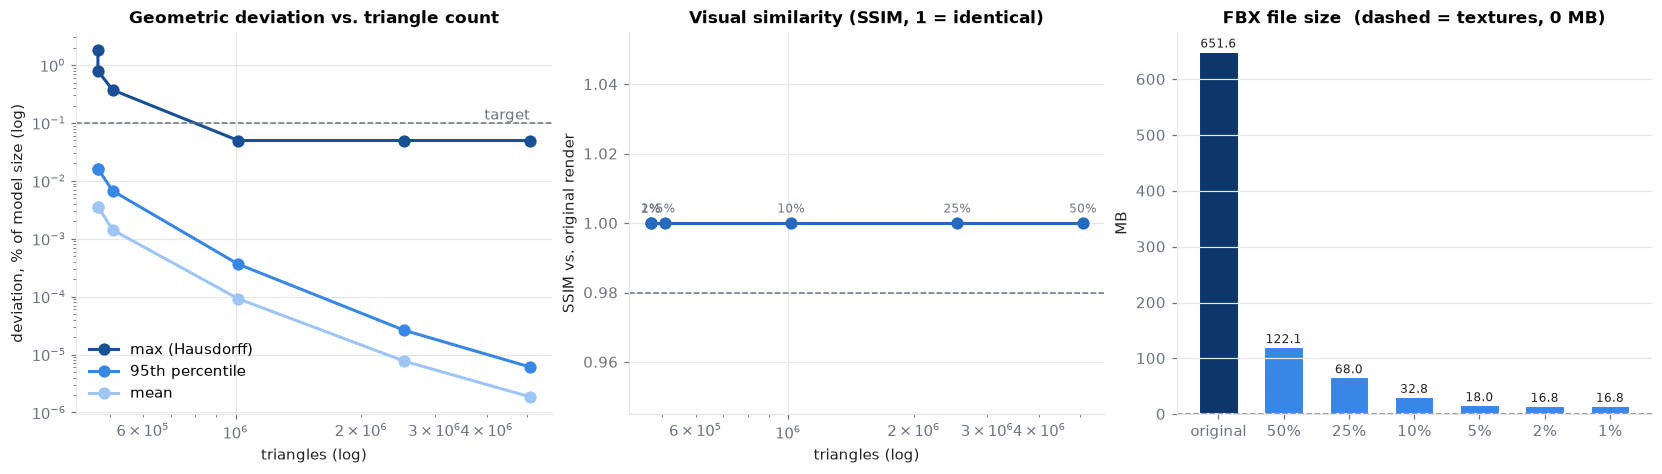

In [9]:
lod = df[df.ratio < 1].copy()
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axs[0]
ax.plot(lod.tris, lod.max_pct, marker="o", ms=7, color=SEQ[1], label="max (Hausdorff)")
ax.plot(lod.tris, lod.p95_pct, marker="o", ms=7, color=SEQ[3], label="95th percentile")
ax.plot(lod.tris, lod.mean_pct, marker="o", ms=7, color=SEQ[5], label="mean")
ax.axhline(MAX_DEVIATION * 100, color=MUTED, ls="--", lw=1)
ax.text(lod.tris.max(), MAX_DEVIATION * 100, " target", color=MUTED, va="bottom", ha="right")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("triangles (log)"); ax.set_ylabel("deviation, % of model size (log)")
ax.set_title("Geometric deviation vs. triangle count"); ax.legend(frameon=False)

ax = axs[1]
ax.plot(lod.tris, lod.ssim, marker="o", ms=7, color=SEQ[2])
for x, y, l in zip(lod.tris, lod.ssim, lod.label):
    ax.annotate(l, (x, y), textcoords="offset points", xytext=(0, 7), ha="center", color=MUTED, fontsize=8)
ax.axhline(MIN_SSIM, color=MUTED, ls="--", lw=1)
ax.set_xscale("log"); ax.set_xlabel("triangles (log)"); ax.set_ylabel("SSIM vs. original render")
ax.set_title("Visual similarity (SSIM, 1 = identical)")

ax = axs[2]
bars = ax.bar(df.label, df.fbx_mb, color=[SEQ[0]] + [SEQ[3]] * len(lod), width=0.62,
              edgecolor="white", linewidth=2)
ax.axhline(tex_mb, color=MUTED, ls="--", lw=1)
for b, v in zip(bars, df.fbx_mb):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}", ha="center", va="bottom", fontsize=8, color=INK)
ax.set_ylabel("MB"); ax.set_title(f"FBX file size  (dashed = textures, {tex_mb:.0f} MB)"); ax.grid(axis="x", visible=False)
plt.show()

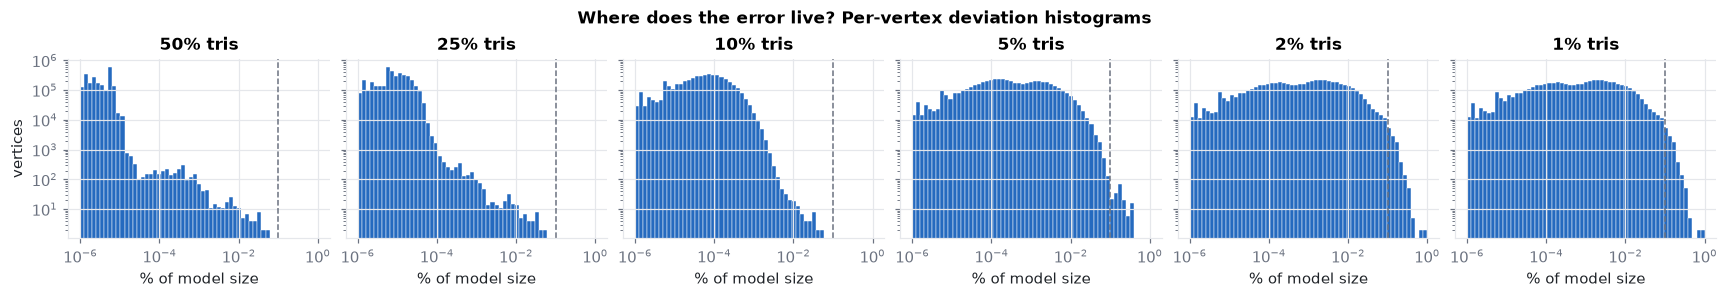

In [10]:
# Distribution of per-vertex deviation (original surface -> LOD), small multiples
fig, axs = plt.subplots(1, len(RATIOS), figsize=(2.6 * len(RATIOS), 2.6), sharey=True)
bins = np.logspace(-6, 0, 60)
for ax, r in zip(axs, RATIOS):
    d = np.clip(DISTS[r], 1e-6, None)
    ax.hist(d, bins=bins, color=SEQ[2], edgecolor="white", linewidth=0.3)
    ax.axvline(MAX_DEVIATION * 100, color=MUTED, ls="--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(f"{r*100:g}% tris")
    ax.set_xlabel("% of model size")
axs[0].set_ylabel("vertices")
fig.suptitle("Where does the error live? Per-vertex deviation histograms", fontweight="bold")
plt.show()

## 7 · Visual comparison

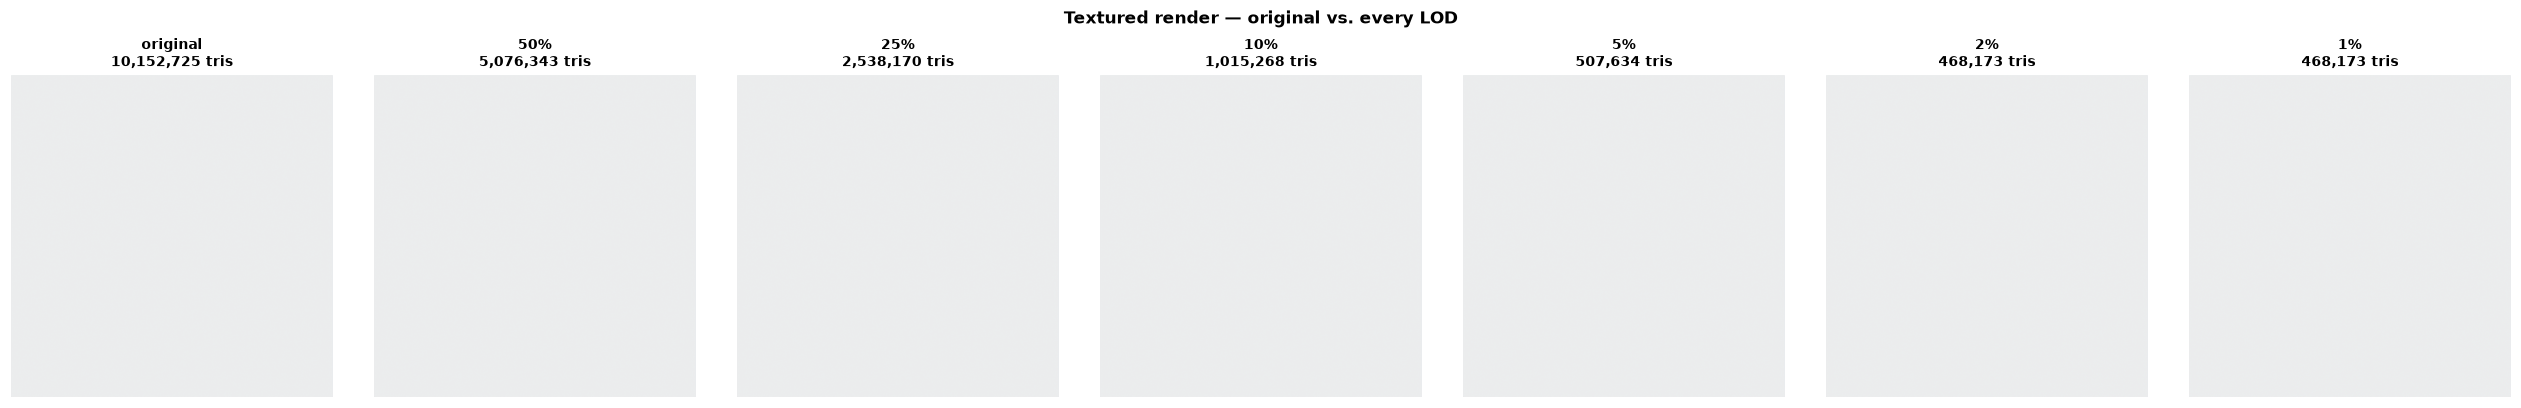

In [11]:
def grid(kind, title, keys=None, crop=None):
    keys = keys or [1.0] + RATIOS
    keys = [k for k in keys if kind in R[k]]
    fig, axs = plt.subplots(1, len(keys), figsize=(3.3 * len(keys), 3.6))
    for ax, k in zip(np.atleast_1d(axs), keys):
        im = load_rgb(R[k][kind])
        if crop: im = im[crop[0]:crop[1], crop[2]:crop[3]]
        ax.imshow(im); ax.axis("off")
        row = df[df.ratio == k].iloc[0]
        ax.set_title(f"{row.label}\n{row.tris:,} tris", fontsize=9)
    fig.suptitle(title, fontweight="bold"); plt.show()

grid("beauty", "Textured render — original vs. every LOD")

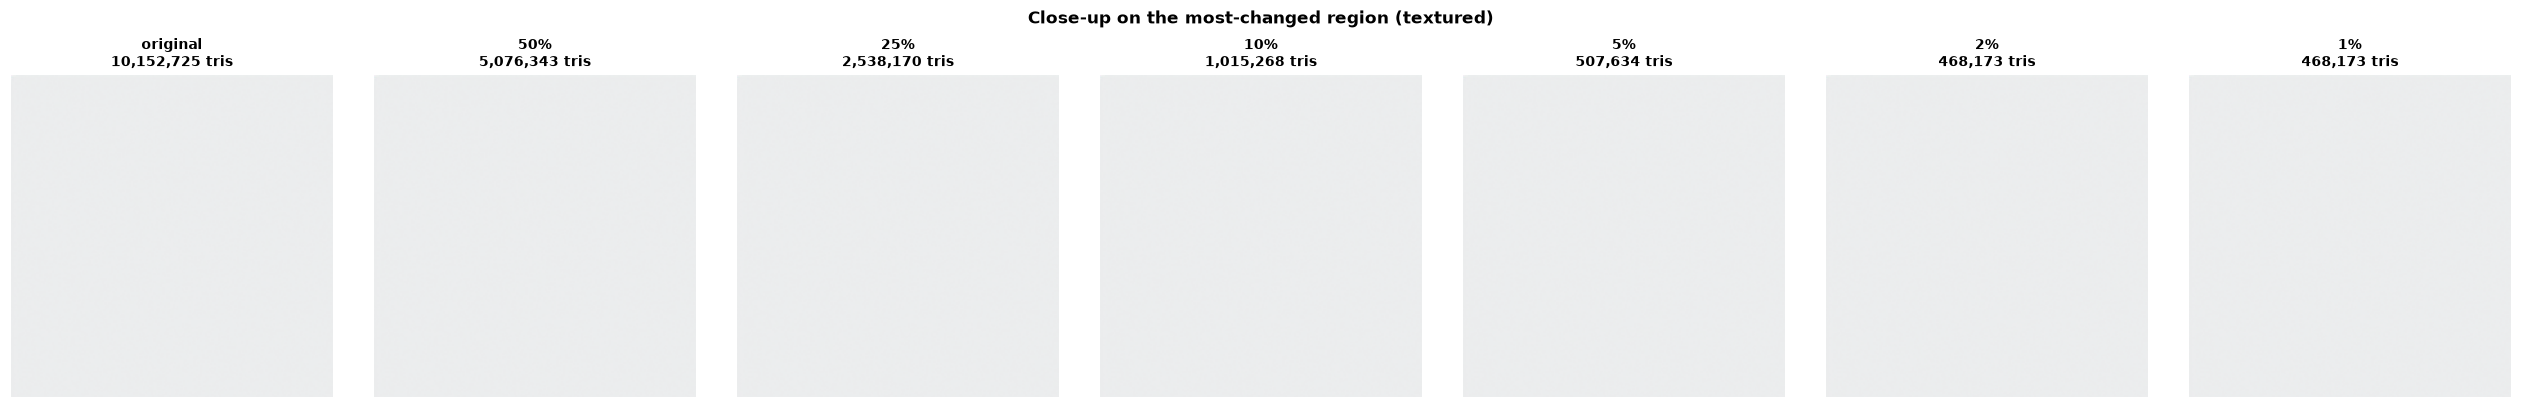

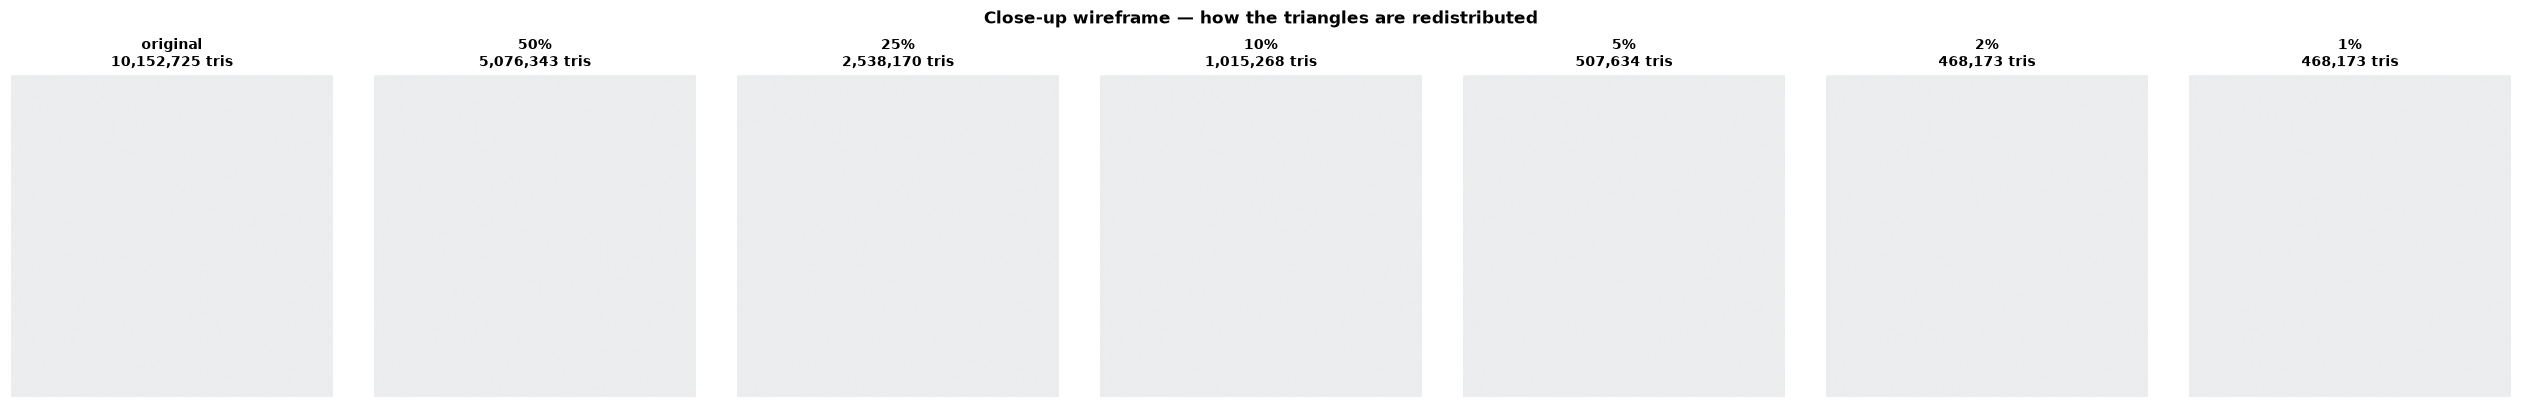

In [12]:
# Automatic close-up: the 256px window where the 2 % LOD differs most from the original
diff = np.abs(load_rgb(R[0.02 if 0.02 in R else RATIOS[-2]]["beauty"]) - REF_IMG).mean(2)
from scipy.ndimage import uniform_filter
S = RENDER_RES // 4
score = uniform_filter(diff, S)
cy, cx = np.unravel_index(score[S//2:-S//2, S//2:-S//2].argmax(), score[S//2:-S//2, S//2:-S//2].shape)
cy, cx = cy + S//2, cx + S//2
CROP = (cy - S//2, cy + S//2, cx - S//2, cx + S//2)
grid("beauty", "Close-up on the most-changed region (textured)", crop=CROP)
grid("wire", "Close-up wireframe — how the triangles are redistributed", crop=CROP)

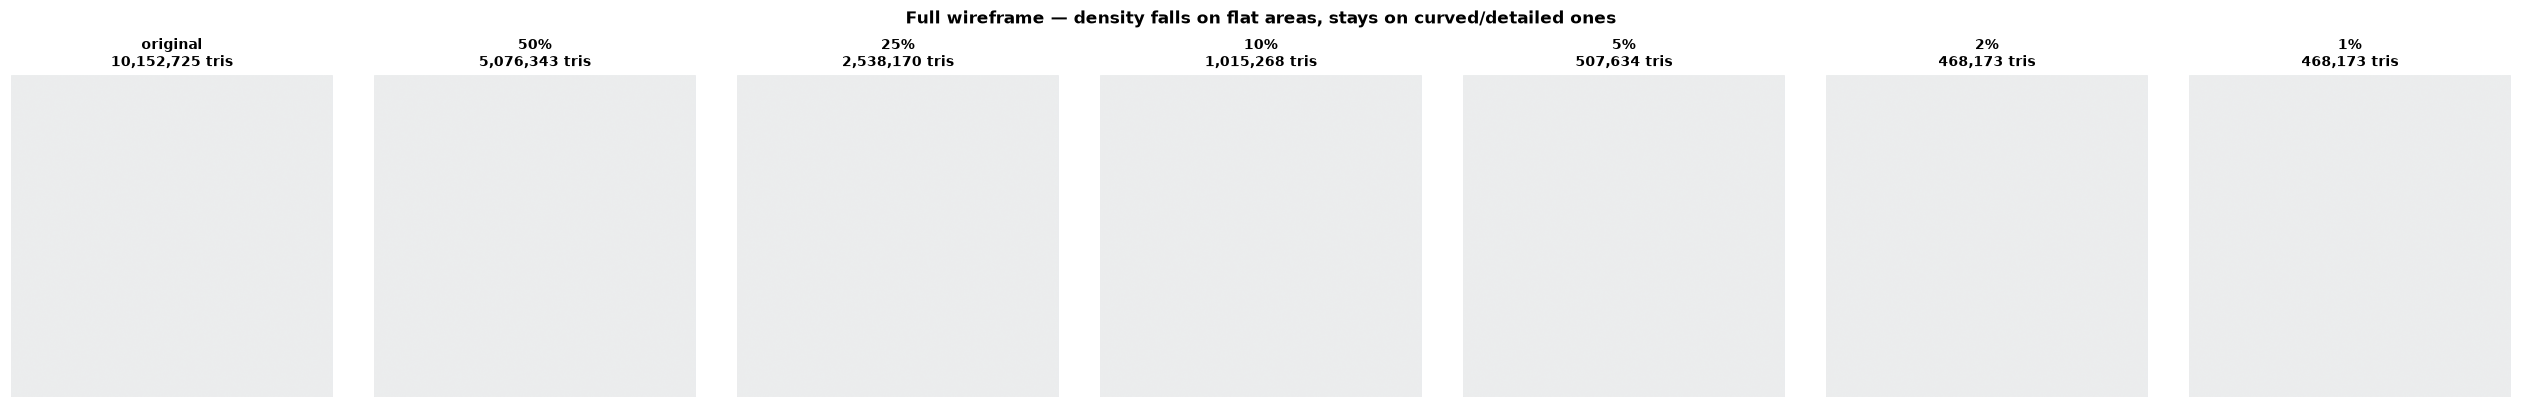

In [13]:
grid("wire", "Full wireframe — density falls on flat areas, stays on curved/detailed ones")

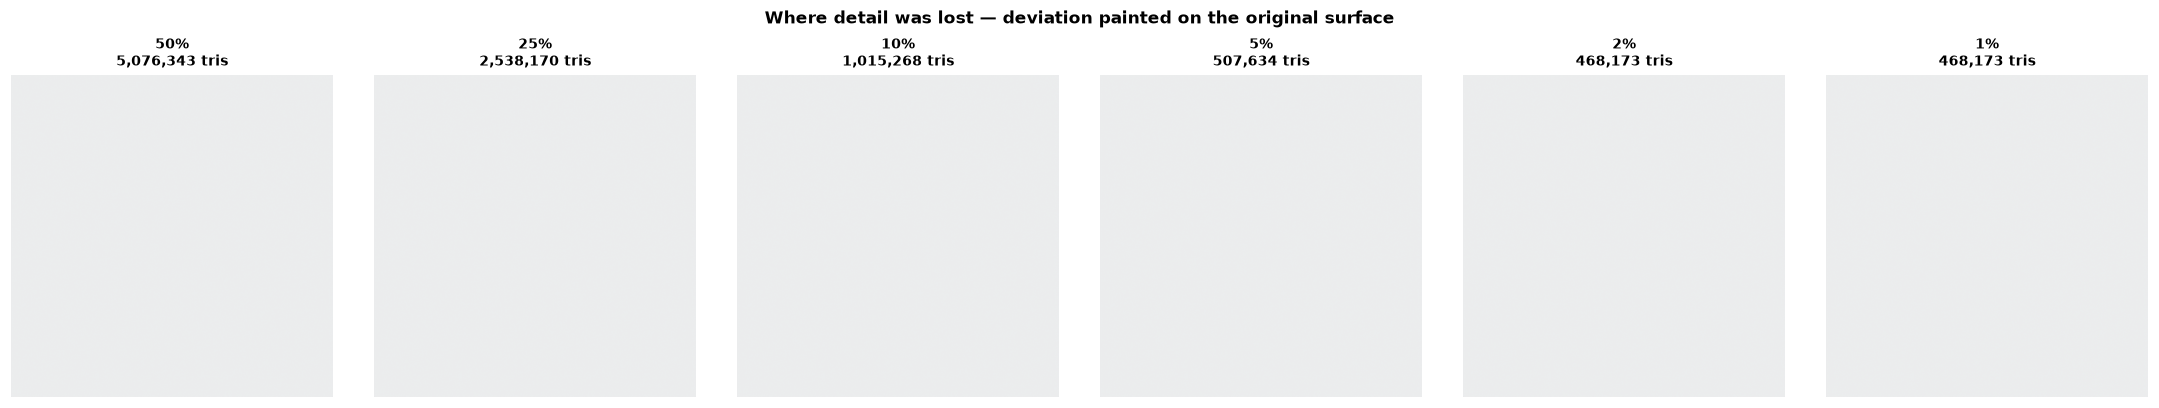

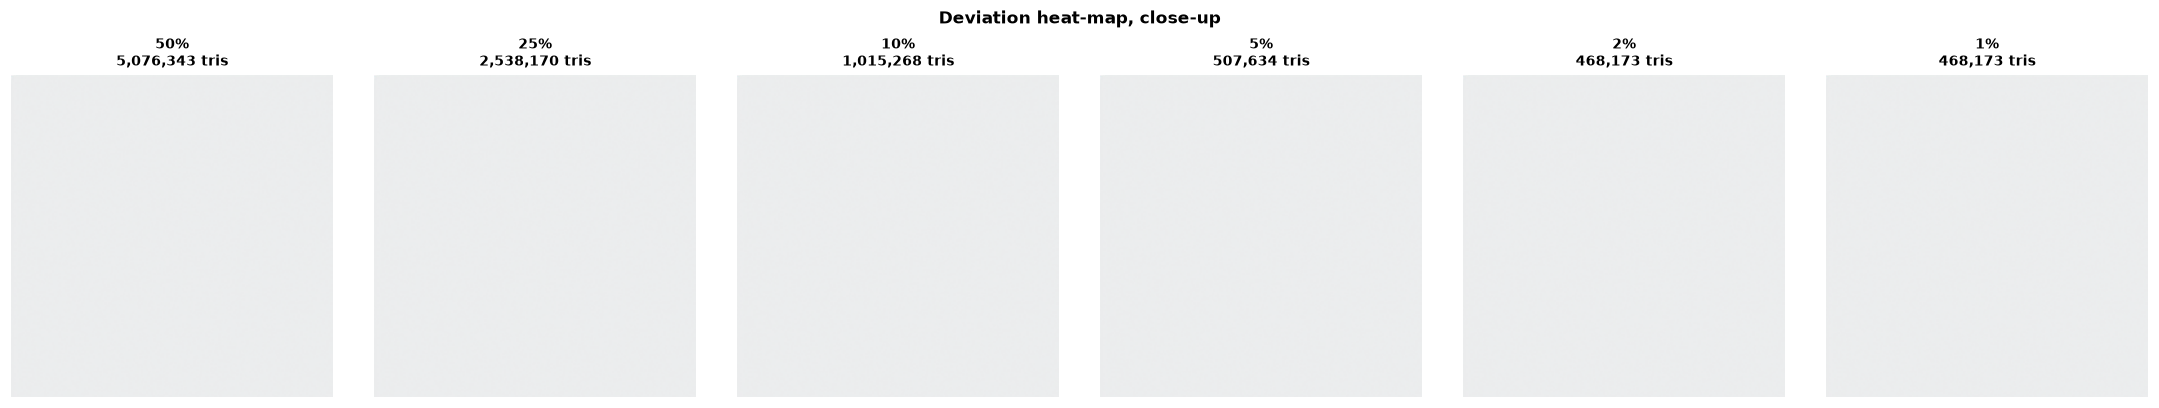

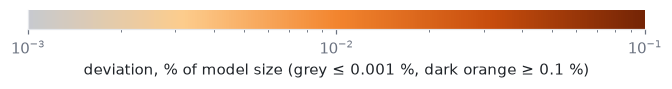

In [14]:
grid("heat", "Where detail was lost — deviation painted on the original surface", keys=RATIOS)
grid("heat", "Deviation heat-map, close-up", keys=RATIOS, crop=CROP)
# colour key (log scale)
fig, ax = plt.subplots(figsize=(6, 0.7))
xs = np.logspace(np.log10(HEAT_LO), np.log10(HEAT_HI), 256)
ax.pcolormesh(xs, [0, 1], heat_colors(heat01(xs))[None, :-1, :3]); ax.set_xscale("log")
ax.set_yticks([]); ax.set_xlabel("deviation, % of model size (grey ≤ 0.001 %, dark orange ≥ 0.1 %)")
ax.grid(False); plt.show()

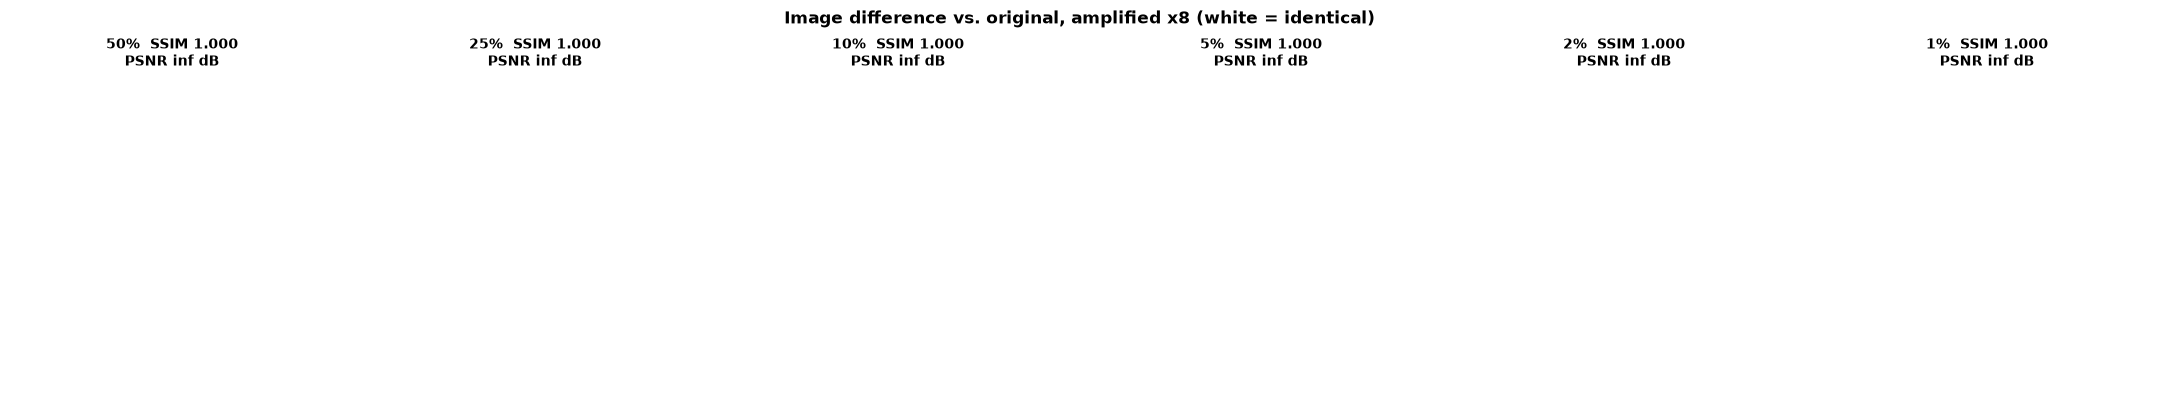

In [15]:
# Pixel difference vs. original render (amplified x8 so small changes are visible)
fig, axs = plt.subplots(1, len(RATIOS), figsize=(3.3 * len(RATIOS), 3.6))
for ax, r in zip(axs, RATIOS):
    d = np.abs(load_rgb(R[r]["beauty"]) - REF_IMG).mean(2)
    ax.imshow(1 - np.clip(d * 8, 0, 1), cmap="gray", vmin=0, vmax=1); ax.axis("off")
    row = df[df.ratio == r].iloc[0]
    ax.set_title(f"{row.label}  SSIM {row.ssim:.3f}\nPSNR {row.psnr:.1f} dB", fontsize=9)
fig.suptitle("Image difference vs. original, amplified x8 (white = identical)", fontweight="bold")
plt.show()

## 8 · Pick the optimal LOD and export

Chooses the **smallest** LOD that satisfies *both* `MAX_DEVIATION` and `MIN_SSIM`, then
exports it as FBX (embedded textures, drop-in replacement) and as GLB with Draco
compression (web/real-time).

Selected: 10%  (1,015,268 tris, max dev 0.0498%, SSIM 1.0000)


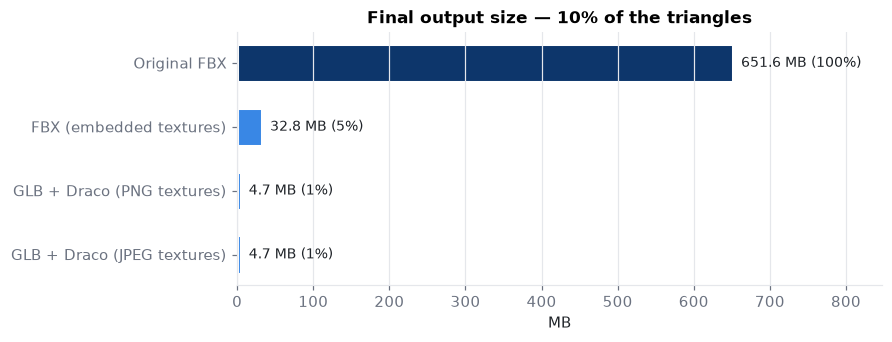

In [16]:
ok = df[(df.ratio < 1) & (df.max_pct <= MAX_DEVIATION * 100) & (df.ssim >= MIN_SSIM)]
if ok.empty:
    best = df[df.ratio < 1].sort_values("ratio").iloc[-1]
    print("No LOD met both targets - using the finest one. Loosen targets or add higher ratios.")
else:
    best = ok.sort_values("tris").iloc[0]
print(f"Selected: {best.label}  ({best.tris:,} tris, max dev {best.max_pct:.4f}%, SSIM {best.ssim:.4f})")

obj.data = ORIG_ME.copy(); decimate(obj, float(best.ratio)); fix_shading(obj)
base = os.path.splitext(os.path.basename(INPUT))[0]
final = {
    "FBX (embedded textures)": export_fbx(obj, f"{OUT_DIR}/{base}_optimized.fbx"),
    "GLB + Draco (PNG textures)": export_glb(obj, f"{OUT_DIR}/{base}_optimized.glb"),
    "GLB + Draco (JPEG textures)": export_glb(obj, f"{OUT_DIR}/{base}_optimized_jpg.glb",
                                              image_format="JPEG"),
}
sizes = pd.Series({"Original FBX": orig_file_mb, **final})

fig, ax = plt.subplots(figsize=(8, 3))
b = ax.barh(sizes.index[::-1], sizes.values[::-1], color=[SEQ[3]] * 3 + [SEQ[0]],
            edgecolor="white", linewidth=2, height=0.6)
for bar, v in zip(b, sizes.values[::-1]):
    ax.text(v, bar.get_y() + bar.get_height() / 2, f"  {v:.1f} MB ({v/orig_file_mb*100:.0f}%)",
            va="center", color=INK, fontsize=9)
ax.set_xlabel("MB"); ax.set_title(f"Final output size — {best.label} of the triangles")
ax.grid(axis="y", visible=False); ax.set_xlim(0, orig_file_mb * 1.3); plt.show()

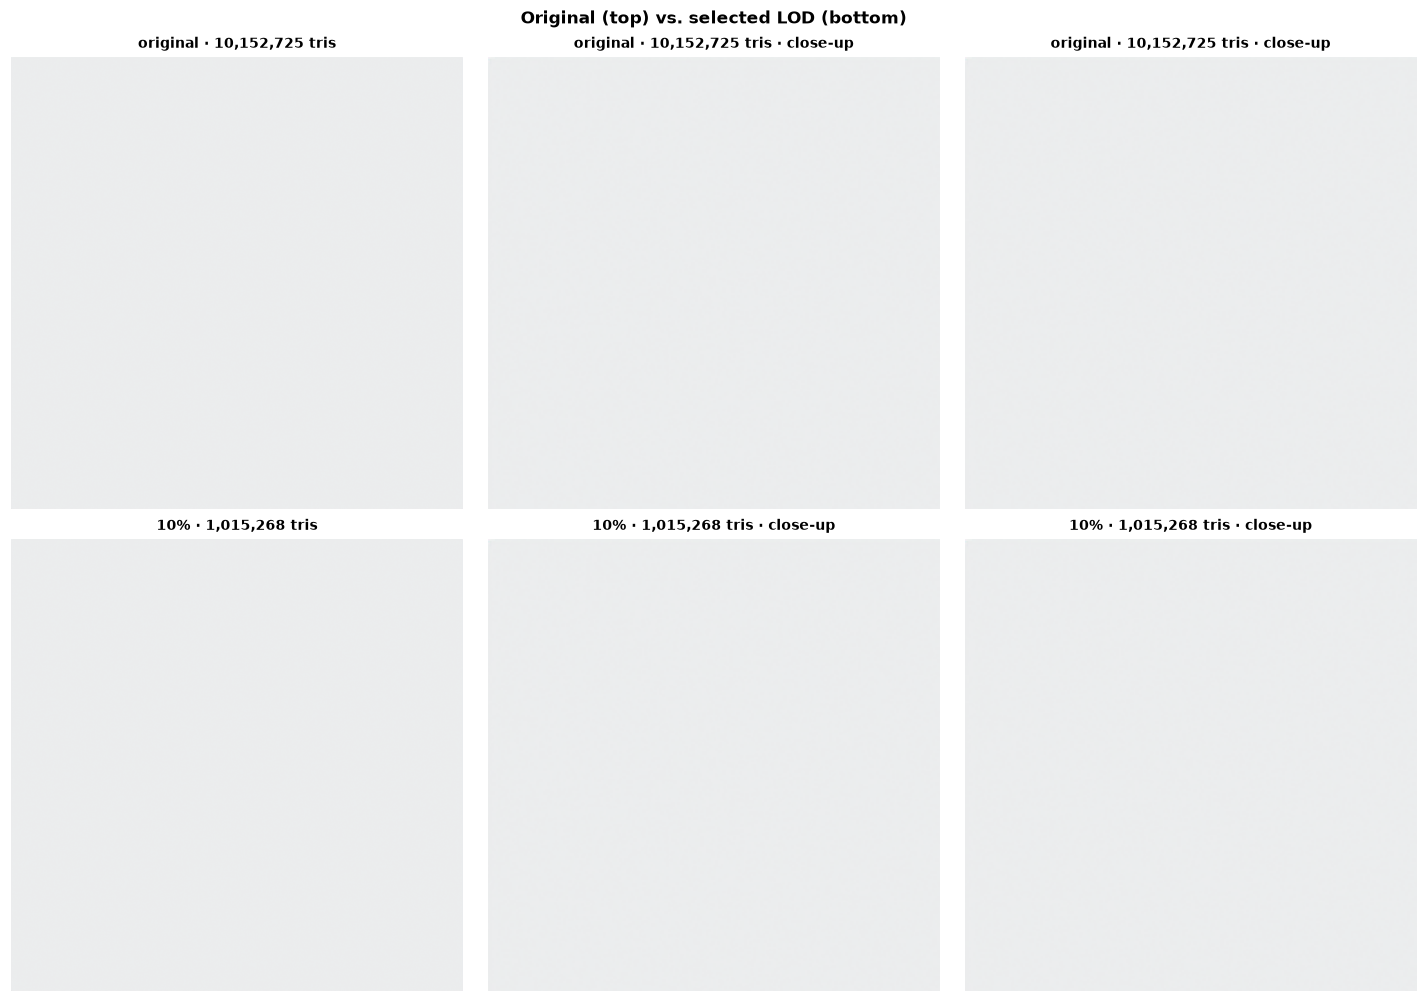

In [17]:
# Side-by-side: original vs. selected LOD, full view + close-up
k = float(best.ratio)
fig, axs = plt.subplots(2, 3, figsize=(13, 9))
for col, (kind, crop) in enumerate([("beauty", None), ("beauty", CROP), ("wire", CROP)]):
    for row, key in enumerate([1.0, k]):
        im = load_rgb(R[key][kind]); im = im[crop[0]:crop[1], crop[2]:crop[3]] if crop else im
        axs[row, col].imshow(im); axs[row, col].axis("off")
        lab = df[df.ratio == key].iloc[0]
        axs[row, col].set_title(f"{lab.label} · {lab.tris:,} tris" + (" · close-up" if crop else ""), fontsize=9)
fig.suptitle("Original (top) vs. selected LOD (bottom)", fontweight="bold")
plt.show()

### Notes
* **Why the look survives:** textures and the normal map are untouched and UVs are interpolated
  during edge collapse, so surface detail keeps coming from the textures while the geometry
  only needs to carry the silhouette.
* **Thin parts (railings, cables, bolts)** are the first to degrade — check the close-ups and the
  heat-map before going below ~5 %.
* **File size floor:** once the geometry is small, the embedded textures dominate. Use the JPEG GLB
  (note: JPEG also re-encodes the normal map — inspect it for banding),
  or downscale textures (`--texture-size 2048` in `optimize_mesh.py`) if you need it smaller.
* The companion CLI script `optimize_mesh.py` does the same pipeline in one command, including an
  automatic `--max-error` search.